# 02 · Plan the slices (query design)

Phase 1 showed three things about GitHub search:
- a user's sentence finds **nothing** (every word has to match);
- one search can only reach **1,000** results;
- most matches are tiny: a 5-star floor keeps **0.9%** of "inventory management".

So we can't just "download GitHub". Phase 2 designs the **queries** that decide what goes into the corpus: which domains, which frameworks, which filters, and how to cut big searches into pieces that each fit under 1,000. It answers *how we get the data*, before Phase 3 spends ~6 hours collecting it.

**Population:** public repositories that match one of our 12 domains together with one of our 12 frameworks, with at least 5 stars, not archived, not a fork.
**Sample:** decided in section 5, once we know how big the population is.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import math
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

from discovery.config import BACKEND, PATHS, SEED, load_config, set_seed

load_dotenv(BACKEND / ".env")          # GITHUB_TOKEN, never printed
set_seed()
cfg = load_config()
DOMAINS, FRAMEWORKS = cfg["collection"]["domains"], cfg["collection"]["frameworks"]
OTHER, OTHER_SHARE = cfg["collection"]["other_topics"], cfg["collection"]["other_share"]
IN = "in:" + ",".join(cfg["collection"]["search_in"])       # where GitHub looks for the words
FLOOR, CAP, TARGET = cfg["collection"]["min_stars"], cfg["collection"]["per_query_cap"], cfg["collection"]["target_size"]
print(f"{len(DOMAINS)} domains × {len(FRAMEWORKS)} frameworks | star floor {FLOOR} | cap {CAP:,} | target {TARGET:,} | seed {SEED}")

12 domains × 12 frameworks | star floor 5 | cap 1,000 | target 10,000 | seed 42


### The search helper, with a cache

Every `total_count` we ask for is an API response, so it is saved in `data/raw/search_counts.json`. Re-running the notebook reuses it and costs no requests. The helper keeps one search every 2.1 s (limit: 30 per minute) and waits out a rate-limit error instead of failing.

In [2]:
API = "https://api.github.com"
session = requests.Session()
session.headers.update({"Accept": "application/vnd.github+json", "X-GitHub-Api-Version": "2022-11-28",
                        "Authorization": f"Bearer {os.environ['GITHUB_TOKEN']}", "User-Agent": "ir-discovery-course-project"})
SEARCH_GAP = 2.1
_last = 0.0


def search(q, page=1, per_page=100):
    """One search page: paced, and retried after a rate-limit response."""
    global _last
    for _ in range(6):
        wait = SEARCH_GAP - (time.monotonic() - _last)
        if wait > 0:
            time.sleep(wait)
        _last = time.monotonic()
        r = session.get(f"{API}/search/repositories", params={"q": q, "page": page, "per_page": per_page}, timeout=30)
        if r.status_code in (403, 429):
            pause = int(r.headers.get("Retry-After") or max(5, int(r.headers.get("X-RateLimit-Reset", time.time() + 60)) - time.time() + 1))
            print(f"rate limited ({r.status_code}), waiting {pause} s")
            time.sleep(pause)
            continue
        r.raise_for_status()
        return r
    raise RuntimeError("still rate limited after 6 tries")


CACHE = PATHS["raw"] / "search_counts.json"
counts_cache = json.loads(CACHE.read_text()) if CACHE.exists() else {}
spent = 0


def count(q):
    """total_count for a query, from the cache if we asked before."""
    global spent
    if q not in counts_cache:
        body = search(q, per_page=1).json()
        counts_cache[q] = {"total_count": body["total_count"], "incomplete": body["incomplete_results"],
                           "asked_at": time.strftime("%Y-%m-%d %H:%M")}
        CACHE.write_text(json.dumps(counts_cache, indent=1))
        spent += 1
    return counts_cache[q]["total_count"]


print("cached counts:", len(counts_cache))

cached counts: 1088


## 1. The filters, one at a time

One slice, `"inventory management" django`, with each filter added in turn. The domain is in quotes so it matches as a phrase; the framework is a plain word.

In [3]:
steps = [
    ("phrase + framework", '"inventory management" django'),
    ("+ stars:>=5", f'"inventory management" django stars:>={FLOOR}'),
    ("+ archived:false", f'"inventory management" django stars:>={FLOOR} archived:false'),
    ("+ fork:false", f'"inventory management" django stars:>={FLOOR} archived:false fork:false'),
    ("+ " + IN, f'"inventory management" django stars:>={FLOOR} archived:false fork:false {IN}'),
]
filters = pd.DataFrame([{"query": label, "total_count": count(q)} for label, q in steps])
filters["kept vs previous"] = (filters["total_count"] / filters["total_count"].shift()).map(lambda x: "" if pd.isna(x) else f"{x:.0%}")
filters.style.format({"total_count": "{:,}"})

,query,total_count,kept vs previous
0,phrase + framework,"1,774",
1,+ stars:>=5,36,2%
2,+ archived:false,36,100%
3,+ fork:false,36,100%
4,"+ in:name,description,topics,readme",219,608%


**What it means:**
- **The star floor** does the cutting: 1,774 → 36 for this slice, about 2%. Most matching repositories are personal or class projects nobody starred.
- **`archived:false` and `fork:false`** change nothing here: repository search already leaves forks out unless you ask, and archived projects with 5+ stars are rare. We keep both in the query anyway, so the rule is written where it is used.
- **`in:…,readme` multiplies it by 6** (36 → 219). By default GitHub only looks at the name, description and topics, but most projects say "built with Django" only in their README. Without it, the slices miss about 5 in 6 relevant repositories. So every query below searches the README too (`search_in` in `config.yaml`).

### Does a slice really find its domain?

GitHub can now match a repository anywhere in its name, description, topics or README. For three slices we read the first 100 results: how many name the domain in the name, description or topics, where it is clearly what the project is about?

In [4]:
def where_it_matches(q, word):
    items = search(q, per_page=100).json()["items"]
    rows = [{"full_name": it["full_name"], "stars": it["stargazers_count"],
             "in name/description/topics": word in f"{it['name']} {it['description'] or ''} {' '.join(it['topics'])}".lower()}
            for it in items]
    return pd.DataFrame(rows)


checks = {}
for d, f, word in [("inventory management", "django", "inventory"), ("e-commerce", "react", "commerce"), ("blog", "nextjs", "blog")]:
    c = where_it_matches(f'"{d}" {f} archived:false fork:false stars:>={FLOOR} {IN}', word)
    checks[f'"{d}" {f}'] = c
    print(f'"{d}" {f}: {c["in name/description/topics"].mean():.0%} of the first {len(c)} say "{word}" in name, description or topics')
misses = pd.concat([c[~c["in name/description/topics"]].assign(slice=k) for k, c in checks.items()])
misses[["slice", "full_name", "stars"]].head(10)

"inventory management" django: 52% of the first 100 say "inventory" in name, description or topics


"e-commerce" react: 68% of the first 100 say "commerce" in name, description or topics


"blog" nextjs: 53% of the first 100 say "blog" in name, description or topics


,slice,full_name,stars
4,"""inventory management"" django",hackstarsj/django-ecommerce-project-amazon-clone,298
7,"""inventory management"" django",arrobalytics/django-ledger,1399
10,"""inventory management"" django",sksoumik/django_resources,53
14,"""inventory management"" django",BekBrace/django_course_2024,34
17,"""inventory management"" django",hacktoolkit/django-htk,140
19,"""inventory management"" django",OmkarPathak/Django-Invoice-Generator,20
21,"""inventory management"" django",iamfoysal/Awesome-Django-Admin-interface,129
22,"""inventory management"" django",ARYANK-08/Kisan.AI,37
23,"""inventory management"" django",manjurulhoque/wowy,219
24,"""inventory management"" django",stretchcloud/claude-code-unified-agents,752


**What it means:** the repositories that don't name the domain in their name, description or topics matched only in the README, often in passing ("it also has a blog section"). They are the **near misses** a good ranker has to push down, so we keep them: that is the noise the search engine exists to handle, not something to remove by hand.

## 2. The 144 slices

Every domain with every framework: `"<domain>" <framework> stars:>=5 archived:false fork:false`. One cheap request each: we only read `total_count`.

In [5]:
def base_query(domain, framework):
    return f'"{domain}" {framework} archived:false fork:false {IN}'


def star_query(base, lo, hi=None):
    return f"{base} stars:>={lo}" if hi is None else f"{base} stars:{lo}..{hi}"


t0 = time.monotonic()
grid = pd.DataFrame([[count(star_query(base_query(d, f), FLOOR)) for f in FRAMEWORKS] for d in DOMAINS],
                    index=DOMAINS, columns=FRAMEWORKS)
print(f"{grid.size} slices | {spent} new requests | {time.monotonic() - t0:.0f} s")
print(f"over {CAP:,}: {(grid > CAP).sum().sum()} slices | empty: {(grid == 0).sum().sum()} | sum of all: {grid.values.sum():,}")

144 slices | 0 new requests | 0 s
over 1,000: 41 slices | empty: 0 | sum of all: 202,567


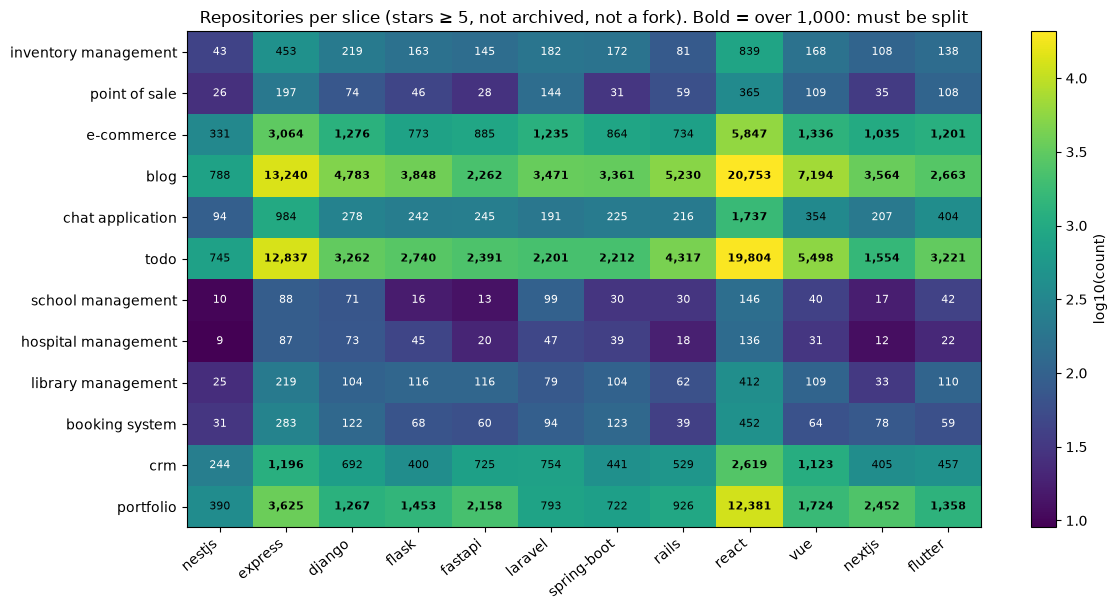

In [6]:
fig, ax = plt.subplots(figsize=(12, 6.2))
im = ax.imshow(np.log10(grid.clip(lower=1)), cmap="viridis", aspect="auto")
ax.set_xticks(range(len(FRAMEWORKS)), FRAMEWORKS, rotation=40, ha="right")
ax.set_yticks(range(len(DOMAINS)), DOMAINS)
for (i, j), v in np.ndenumerate(grid.values):
    ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8,
            color="white" if v < 300 else "black", fontweight="bold" if v > CAP else "normal")
ax.set_title(f"Repositories per slice (stars ≥ {FLOOR}, not archived, not a fork). Bold = over {CAP:,}: must be split")
fig.colorbar(im, ax=ax, label="log10(count)")
plt.tight_layout()

## 3. Split the big slices, recursively by star range

A slice over 1,000 can't be paged to the end. Instead of fixed star bands, we **halve the star range until every piece fits**:

1. Ask for the count of `stars:lo..hi`.
2. Under 1,000: that piece is done.
3. Over: split the range at its middle and do the same for both halves.

The middle is taken on a **log scale** (√(lo × hi)), because stars are very skewed: there are far more repositories with 5–20 stars than with 500–2,000. A piece with one star value (say exactly 5) that is still over 1,000 can't be split by stars any more; then it is halved by **creation date** the same way.

In [7]:
TOP = 1_000_000     # above any repository's stars: stars:>=lo is the same as lo..TOP


def split(base, lo=FLOOR, hi=None, depth=0, log=None):
    """Pieces (lo, hi, count) of one slice, each at most CAP."""
    n = count(star_query(base, lo, hi))
    if log is not None:
        log.append(f"{'    ' * depth}stars {lo}..{hi or '∞'}: {n:,}" + ("  ✓" if n <= CAP else "  → split"))
    if n <= CAP:
        return [(lo, hi, n, None, None)]
    top = hi or TOP
    if lo == top:                       # one star value left: halve by creation date instead
        return [(lo, hi, n, d0, d1) for d0, d1, n in split_dates(star_query(base, lo, hi), depth + 1, log)]
    mid = int(round(math.sqrt(lo * top)))
    mid = max(lo, min(top - 1, mid))
    return split(base, lo, mid, depth + 1, log) + split(base, mid + 1, hi, depth + 1, log)


def split_dates(q, depth, log, d0=pd.Timestamp("2008-01-01"), d1=None):
    """Halve a query by created: date until each part is at most CAP."""
    d1 = d1 or pd.Timestamp.today().normalize()
    n = count(f"{q} created:{d0:%Y-%m-%d}..{d1:%Y-%m-%d}")
    if log is not None:
        log.append(f"{'    ' * depth}created {d0:%Y-%m-%d}..{d1:%Y-%m-%d}: {n:,}" + ("  ✓" if n <= CAP else "  → split"))
    if n <= CAP or d0 == d1:
        return [(f"{d0:%Y-%m-%d}", f"{d1:%Y-%m-%d}", n)]
    mid = d0 + (d1 - d0) / 2
    mid = mid.normalize()
    return split_dates(q, depth + 1, log, d0, mid) + split_dates(q, depth + 1, log, mid + pd.Timedelta(days=1), d1)


# the biggest slice, step by step
big_d, big_f = grid.stack().idxmax()
log = []
pieces = split(base_query(big_d, big_f), log=log)
print(f'"{big_d}" {big_f}:')
print("\n".join(log))
print(f"→ {len(pieces)} pieces, {sum(p[2] for p in pieces):,} repositories, largest {max(p[2] for p in pieces):,}")

"blog" react:
stars 5..∞: 20,753  → split
    stars 5..2236: 20,070  → split
        stars 5..106: 16,802  → split
            stars 5..23: 12,260  → split
                stars 5..11: 8,503  → split
                    stars 5..7: 5,365  → split
                        stars 5..6: 4,067  → split
                            stars 5..5: 2,389  → split
                                created 2008-01-01..2026-11-23: 2,389  → split
                                    created 2008-01-01..2017-06-12: 184  ✓
                                    created 2017-06-13..2026-11-23: 2,205  → split
                                        created 2017-06-13..2022-03-04: 865  ✓
                                        created 2022-03-05..2026-11-23: 1,340  → split
                                            created 2022-03-05..2024-07-14: 552  ✓
                                            created 2024-07-15..2026-11-23: 788  ✓
                            stars 6..6: 1,678  → split
                       

In [8]:
rows = []
t0 = time.monotonic(); spent_before = spent
for d in DOMAINS:
    for f in FRAMEWORKS:
        for lo, hi, n, d0, d1 in split(base_query(d, f)):
            q = star_query(base_query(d, f), lo, hi) + (f" created:{d0}..{d1}" if d0 else "")
            rows.append({"domain": d, "framework": f, "stars_lo": lo, "stars_hi": hi, "created": f"{d0}..{d1}" if d0 else "", "count": n, "query": q})
leaves = pd.DataFrame(rows)
print(f"{len(leaves)} search pieces from {grid.size} slices | {spent - spent_before} new requests | {time.monotonic() - t0:.0f} s")
print(f"sum of pieces {leaves['count'].sum():,} vs sum of slices {grid.values.sum():,} | largest piece {leaves['count'].max():,} | over {CAP:,}: {(leaves['count'] > CAP).sum()}")
leaves.groupby(["domain", "framework"]).size().value_counts().sort_index().rename("slices").rename_axis("pieces per slice").to_frame().T

442 search pieces from 144 slices | 0 new requests | 0 s
sum of pieces 202,569 vs sum of slices 202,567 | largest piece 998 | over 1,000: 0


pieces per slice,1,3,4,5,6,7,8,9,10,11,12,19,21,23,30,34
slices,103,3,6,7,11,4,1,1,1,1,1,1,1,1,1,1


**What it means:** the pieces add up to (almost) the same total as the slices, so splitting lost nothing, and every piece can now be paged to its end in Phase 3. Small differences come from counts drifting between requests (people star and archive repositories every day) and from GitHub's counts being estimates on large searches.

## 4. How big is the population?

The sum counts a repository once **per slice it matches**: a Next.js e-commerce site with React in its README is in both `e-commerce nextjs` and `e-commerce react`. So the sum is an **upper bound**; the real number of distinct repositories is only known after Phase 3 lists them and removes duplicates.

population (upper bound): 202,567 | target 10,000
smallest domain: hospital management 539 | smallest framework: nestjs 2,736


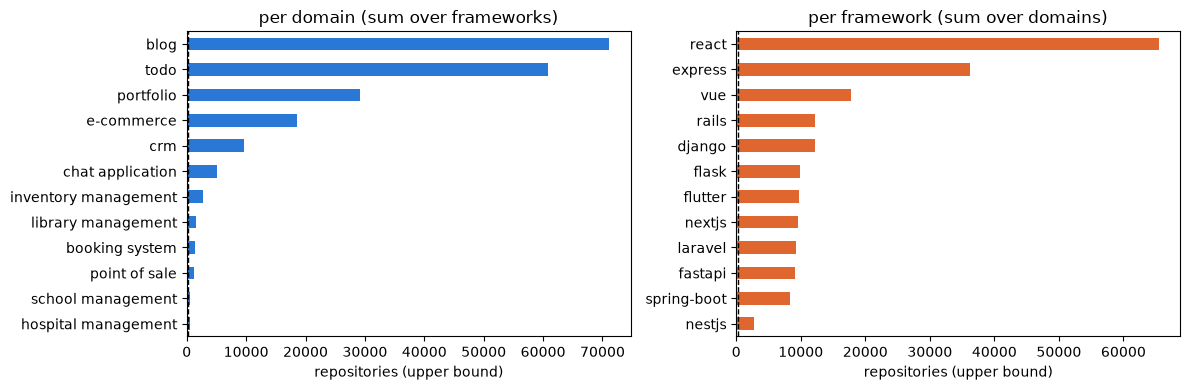

In [9]:
per_domain = grid.sum(axis=1).sort_values()
per_fw = grid.sum(axis=0).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
per_domain.plot.barh(ax=ax[0], color="#2a78d6"); ax[0].set_title("per domain (sum over frameworks)")
per_fw.plot.barh(ax=ax[1], color="#e0662f"); ax[1].set_title("per framework (sum over domains)")
for a in ax:
    a.axvline(200, color="black", ls="--", lw=1); a.set_xlabel("repositories (upper bound)")
plt.tight_layout()
print(f"population (upper bound): {grid.values.sum():,} | target {TARGET:,}")
print("smallest domain:", per_domain.index[0], f"{per_domain.iloc[0]:,}", "| smallest framework:", per_fw.index[0], f"{per_fw.iloc[0]:,}")

### How much of each domain do our 12 frameworks reach?

The slices only find repositories that mention one of our 12 frameworks. A Java, plain PHP or C# inventory system is in none of them. Asking each domain on its own (one request each) shows how much we reach. The framework sum can count a repository twice, so "reached" is an upper bound.

In [10]:
cover = pd.DataFrame({"domain alone": [count(f'"{d}" archived:false fork:false stars:>={FLOOR} {IN}') for d in DOMAINS],
                      "in our 12 slices (sum)": grid.sum(axis=1).values}, index=DOMAINS)
cover["reached (upper bound)"] = (cover["in our 12 slices (sum)"] / cover["domain alone"]).map("{:.0%}".format)
cover.loc["all domains"] = [cover["domain alone"].sum(), cover["in our 12 slices (sum)"].sum(), f'{cover["in our 12 slices (sum)"].sum() / cover["domain alone"].sum():.0%}']
cover.style.format({"domain alone": "{:,}", "in our 12 slices (sum)": "{:,}"})

,domain alone,in our 12 slices (sum),reached (upper bound)
inventory management,"3,595","2,711",75%
point of sale,"1,574","1,222",78%
e-commerce,"21,310","18,581",87%
blog,"197,731","71,157",36%
chat application,"5,831","5,177",89%
todo,"195,985","60,782",31%
school management,700,602,86%
hospital management,739,539,73%
library management,"2,640","1,489",56%
booking system,"1,678","1,473",88%


## 5. From population to sample: a quota per slice

The population is far bigger than our 10,000 target, and very uneven: a few slices (React, portfolios, e-commerce) are huge, many are small. Two ways to shrink it:

| Option | Effect | Problem |
|---|---|---|
| Raise the star floor | keeps popular projects only | the small, beginner-level projects we want to find disappear first |
| **A cap per slice** | big slices are cut down, small slices are kept whole | none for our goal: every domain × framework stays in |

We use a **cap per slice**: find the one number Q such that taking `min(slice size, Q)` from every slice adds up to the target. Small slices are kept whole; big ones give Q repositories, picked **at random** (seed 42) from the full listing in Phase 3, not the top by stars, so we keep the natural mix of popular and small projects, as in the ML subset.

The target for the domain slices is 90% of 10,000; the other 10% are unrelated repositories (section 6). We aim a little higher (×1.15) to allow for duplicates between slices.

In [11]:
DUP_ALLOWANCE = 1.15
domain_target = int(TARGET * (1 - OTHER_SHARE) * DUP_ALLOWANCE)

sizes = grid.stack()
lo_q, hi_q = 0, int(sizes.max())
while lo_q < hi_q:                       # smallest Q with sum(min(size, Q)) >= target
    mid = (lo_q + hi_q) // 2
    if np.minimum(sizes, mid).sum() >= domain_target:
        hi_q = mid
    else:
        lo_q = mid + 1
Q = lo_q
quota = np.minimum(sizes, Q).rename("take")
print(f"domain target {domain_target:,} (incl. ×{DUP_ALLOWANCE} for duplicates) → Q = {Q} per slice")
print(f"slices kept whole: {(sizes <= Q).sum()} of {len(sizes)} | slices capped at {Q}: {(sizes > Q).sum()} | total to take: {quota.sum():,}")

domain target 10,350 (incl. ×1.15 for duplicates) → Q = 84 per slice
slices kept whole: 39 of 144 | slices capped at 84: 105 | total to take: 10,426


In [12]:
take = quota.unstack()[FRAMEWORKS].loc[DOMAINS]
check = pd.concat([take.sum(axis=1).rename("per domain"), take.sum(axis=0).rename("per framework")], axis=1)
print("every domain ≥ 200:", bool((take.sum(axis=1) >= 200).all()), "| every framework ≥ 200:", bool((take.sum(axis=0) >= 200).all()))
pd.DataFrame({"per domain": take.sum(axis=1)}).T

every domain ≥ 200: True | every framework ≥ 200: True


,inventory management,point of sale,e-commerce,blog,chat application,todo,school management,hospital management,library management,booking system,crm,portfolio
per domain,964,719,1008,1008,1008,1008,521,484,871,819,1008,1008


In [13]:
pd.DataFrame({"per framework": take.sum(axis=0)}).T

,nestjs,express,django,flask,fastapi,laravel,spring-boot,rails,react,vue,nextjs,flutter
per framework,648,1008,974,847,793,966,856,793,1008,891,763,879


## 6. The "other" repositories (~10%)

If every repository in the corpus is about one of our 12 domains, a query can never show that it ignores unrelated projects. So about 10% of the corpus comes from **unrelated** searches: games, tools, editors. They are the clear non-relevant results that a good ranking has to keep at the bottom. Same filters, no framework. The topics and the 10% are set in `config.yaml` (`other_topics`, `other_share`), next to the domains and frameworks.

In [14]:
# topics and share come from config.yaml: collection.other_topics, collection.other_share
other_n = int(TARGET * OTHER_SHARE)
other = pd.DataFrame([{"domain": "other", "framework": "", "query": f'"{q}" archived:false fork:false {IN} stars:>={FLOOR}',
                       "topic": q, "count": count(f'"{q}" archived:false fork:false {IN} stars:>={FLOOR}')} for q in OTHER])
other["take"] = np.minimum(other["count"], other_n // len(OTHER))
other[["topic", "count", "take"]].style.format({"count": "{:,}"})

,topic,count,take
0,game,"245,820",100
1,weather app,"3,258",100
2,music player,"8,667",100
3,calculator,"32,554",100
4,url shortener,"3,167",100
5,markdown editor,"4,488",100
6,password manager,"5,300",100
7,image editor,"2,831",100
8,file manager,"12,976",100
9,compiler,"457,358",100


## 7. Freeze the plan

Like the frozen split in the ML project: the slice list is saved once, committed to git, and Phase 3 reads it, so everyone collects from exactly the same queries even if GitHub's counts move a little. Each piece carries its share of its slice's quota.

In [15]:
leaves["slice_size"] = leaves.groupby(["domain", "framework"])["count"].transform("sum")
leaves["slice_take"] = [quota[(d, f)] for d, f in zip(leaves["domain"], leaves["framework"])]
leaves["take"] = (leaves["count"] / leaves["slice_size"].replace(0, 1) * leaves["slice_take"]).round().astype(int)
plan = pd.concat([
    leaves[["domain", "framework", "stars_lo", "stars_hi", "created", "count", "take", "query"]],
    other[["domain", "framework", "count", "take", "query"]].assign(stars_lo=FLOOR, stars_hi=None, created=""),
], ignore_index=True)
plan["stars_hi"] = plan["stars_hi"].astype("Int64")
plan.insert(0, "piece_id", [f"p{i:03d}" for i in range(len(plan))])
OUT = BACKEND / "config" / "slices.csv"
plan.to_csv(OUT, index=False)
reachable = np.minimum(plan["count"], CAP)
print(f"saved {OUT.relative_to(BACKEND)}: {len(plan)} search pieces | to take {plan['take'].sum():,} | "
      f"reachable {reachable.sum():,} | search pages to list them all ≤ {int(np.ceil(reachable / 100).sum()):,} "
      f"(≈{np.ceil(reachable / 100).sum() * SEARCH_GAP / 60:.0f} min)")
plan.sample(6, random_state=SEED)

saved config/slices.csv: 452 search pieces | to take 11,421 | reachable 212,569 | search pages to list them all ≤ 2,345 (≈82 min)


,piece_id,domain,framework,stars_lo,stars_hi,created,count,take,query
299,p299,todo,nextjs,12,23,,300,16,"""todo"" nextjs archived:false fork:false in:nam..."
39,p039,e-commerce,laravel,24,106,,261,18,"""e-commerce"" laravel archived:false fork:false..."
336,p336,library management,flask,5,<NA>,,116,84,"""library management"" flask archived:false fork..."
332,p332,hospital management,flutter,5,<NA>,,22,22,"""hospital management"" flutter archived:false f..."
153,p153,blog,react,75,106,,779,3,"""blog"" react archived:false fork:false in:name..."
196,p196,chat application,vue,5,<NA>,,354,84,"""chat application"" vue archived:false fork:fal..."


In [16]:
summary = pd.DataFrame({
    "Decision": ["Target size", "Domains", "Frameworks", "Search fields", "Search slices", "Search pieces after splitting",
                 "Minimum stars", "Archived repos", "Forks", "Per-slice cap (Q)", "Unrelated repos",
                 "Population (upper bound)", "Planned sample"],
    "Value": [f"~{TARGET:,} repositories", len(DOMAINS), len(FRAMEWORKS), IN, f"{grid.size} ({(grid > CAP).sum().sum()} over {CAP:,})",
              f"{len(leaves)}", FLOOR, "excluded (archived:false)", "excluded (fork:false)", Q,
              f"{other['take'].sum():,} ({OTHER_SHARE:.0%}) from {len(OTHER)} unrelated searches",
              f"{grid.values.sum():,}", f"{plan['take'].sum():,} before removing duplicates"],
})
summary

,Decision,Value
0,Target size,"~10,000 repositories"
1,Domains,12
2,Frameworks,12
3,Search fields,"in:name,description,topics,readme"
4,Search slices,"144 (41 over 1,000)"
5,Search pieces after splitting,442
6,Minimum stars,5
7,Archived repos,excluded (archived:false)
8,Forks,excluded (fork:false)
9,Per-slice cap (Q),84


## 8. What we found, in charts

Everything below reuses the counts already cached, plus a few new ones: each domain with no star floor, and each domain by star band.

### 8.1 How many did we find? From "everything GitHub matches" to our sample

Summed over the 12 domains: every repository that mentions a domain, then what each filter and decision keeps.

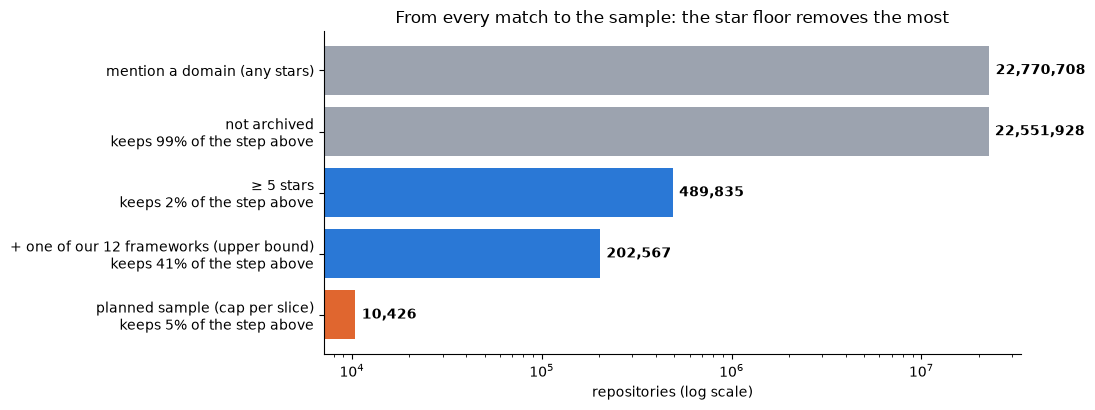

In [17]:
any_n = sum(count(f'"{d}" fork:false {IN}') for d in DOMAINS)
live_n = sum(count(f'"{d}" archived:false fork:false {IN}') for d in DOMAINS)
floor_n = int(cover["domain alone"].iloc[:-1].sum())
slices_n = int(grid.values.sum())
take_n = int(quota.sum())
steps = [("mention a domain (any stars)", any_n), ("not archived", live_n), (f"≥ {FLOOR} stars", floor_n),
         ("+ one of our 12 frameworks (upper bound)", slices_n), ("planned sample (cap per slice)", take_n)]
funnel = pd.Series({name + ("" if i == 0 else f"\nkeeps {v / steps[i - 1][1]:.0%} of the step above"): v
                    for i, (name, v) in enumerate(steps)})
fig, ax = plt.subplots(figsize=(11, 4.2))
colors = ["#9ca3af", "#9ca3af", "#2a78d6", "#2a78d6", "#e0662f"]
bars = ax.barh(funnel.index[::-1], funnel.values[::-1], color=colors[::-1])
ax.set_xscale("log")
for b, v in zip(bars, funnel.values[::-1]):
    ax.text(v * 1.08, b.get_y() + b.get_height() / 2, f"{v:,}", va="center", fontsize=10, fontweight="bold")
ax.set_xlabel("repositories (log scale)")
ax.set_title("From every match to the sample: the star floor removes the most")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### 8.2 Which domains go with which frameworks?

Left: for each domain, how its repositories split across the 12 frameworks (each row adds up to 100%). Right: **lift**, how much more (red) or less (blue) often a domain and a framework appear together than if frameworks were spread evenly across domains. Lift 2 = twice as often as expected.

strongest pairs: school management + laravel (3.6×), point of sale + laravel (2.6×), hospital management + django (2.2×), booking system + spring-boot (2.0×), school management + django (2.0×)
weakest pairs (with repos): inventory management + rails (0.49×), school management + fastapi (0.48×), hospital management + nextjs (0.47×), library management + nextjs (0.47×), booking system + rails (0.44×)


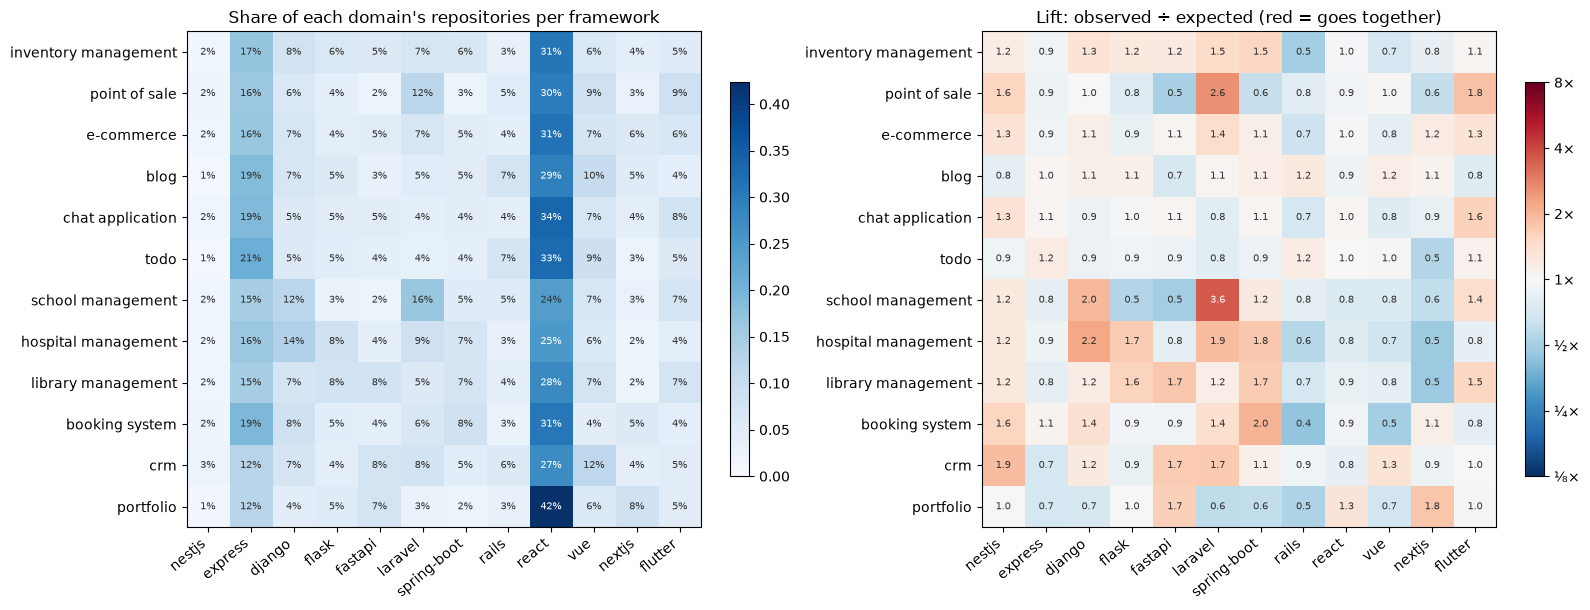

In [18]:
share = grid.div(grid.sum(axis=1), axis=0)
expected = np.outer(grid.sum(axis=1), grid.sum(axis=0)) / grid.values.sum()
lift = grid / expected

fig, ax = plt.subplots(1, 2, figsize=(16, 6.2))
im0 = ax[0].imshow(share, cmap="Blues", aspect="auto", vmin=0)
for (i, j), v in np.ndenumerate(share.values):
    ax[0].text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7.5, color="white" if v > 0.25 else "#333")
ax[0].set_title("Share of each domain's repositories per framework")
fig.colorbar(im0, ax=ax[0], fraction=0.035)
im1 = ax[1].imshow(np.log2(lift.clip(lower=1 / 8)), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
for (i, j), v in np.ndenumerate(lift.values):
    ax[1].text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5, color="white" if abs(np.log2(max(v, 1 / 8))) > 1.8 else "#333")
ax[1].set_title("Lift: observed ÷ expected (red = goes together)")
cb = fig.colorbar(im1, ax=ax[1], fraction=0.035, ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.ax.set_yticklabels(["⅛×", "¼×", "½×", "1×", "2×", "4×", "8×"])
for a in ax:
    a.set_xticks(range(len(FRAMEWORKS)), FRAMEWORKS, rotation=40, ha="right")
    a.set_yticks(range(len(DOMAINS)), DOMAINS)
plt.tight_layout()
top = lift.stack().sort_values(ascending=False)
print("strongest pairs:", ", ".join(f"{d} + {f} ({v:.1f}×)" for (d, f), v in top.head(5).items()))
print("weakest pairs (with repos):", ", ".join(f"{d} + {f} ({v:.2f}×)" for (d, f), v in top[top > 0].tail(5).items()))

### 8.3 What is the data like? Stars are very skewed

Each domain's repositories (≥ 5 stars) by star band. Most projects sit just above the floor: the corpus will be mostly small projects, with a thin tail of famous ones. That is what we want for "beginner-friendly" queries, and it is why popularity has to be on a log scale in Phase 12.

5–19 stars: 61% of all | 500+: 4.2%


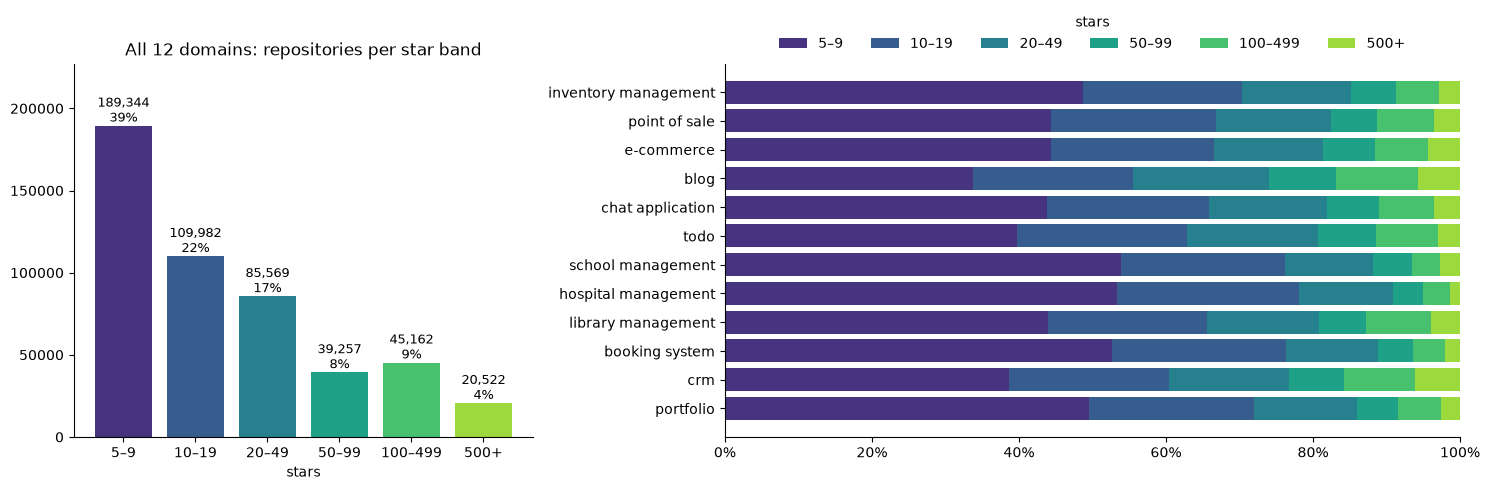

In [19]:
BANDS = [(5, 9), (10, 19), (20, 49), (50, 99), (100, 499), (500, None)]
band_names = [f"{lo}–{hi}" if hi else f"{lo}+" for lo, hi in BANDS]
bands = pd.DataFrame([[count(f'"{d}" archived:false fork:false {IN} ' + (f"stars:{lo}..{hi}" if hi else f"stars:>={lo}"))
                       for lo, hi in BANDS] for d in DOMAINS], index=DOMAINS, columns=band_names)
pct = bands.div(bands.sum(axis=1), axis=0)

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})
tot = bands.sum()
ax[0].bar(band_names, tot, color=plt.cm.viridis(np.linspace(0.15, 0.85, len(BANDS))))
for i, v in enumerate(tot):
    ax[0].text(i, v, f"{v:,}\n{v / tot.sum():.0%}", ha="center", va="bottom", fontsize=9)
ax[0].set_title("All 12 domains: repositories per star band")
ax[0].set_xlabel("stars"); ax[0].set_ylim(0, tot.max() * 1.2)
left = np.zeros(len(DOMAINS))
for k, (c, col) in enumerate(zip(band_names, plt.cm.viridis(np.linspace(0.15, 0.85, len(BANDS))))):
    ax[1].barh(DOMAINS, pct[c], left=left, color=col, label=c)
    left += pct[c].values
ax[1].invert_yaxis(); ax[1].set_xlim(0, 1)
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax[1].legend(title="stars", ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
print(f"5–19 stars: {(tot.iloc[0] + tot.iloc[1]) / tot.sum():.0%} of all | 500+: {tot.iloc[-1] / tot.sum():.1%}")

### 8.4 What is *not* in the corpus

For each domain (≥ 5 stars): the part our 12 framework slices reach, and the part they miss: projects in other stacks (plain PHP, Java without Spring, C#, Go, …) or that never name a framework. They stay out on purpose: our queries ask for these 12 stacks.

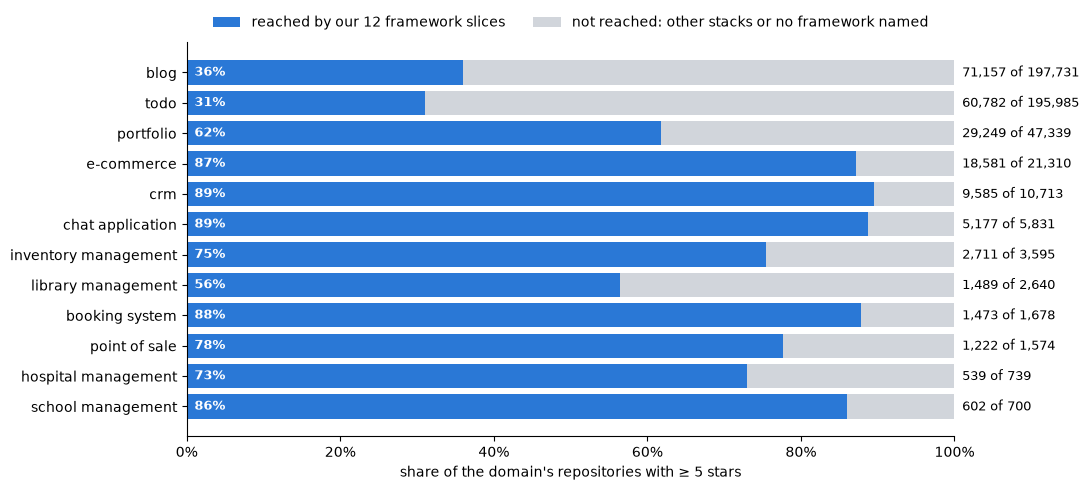

In [20]:
reach = cover.iloc[:-1].copy()
reach["reached"] = np.minimum(reach["in our 12 slices (sum)"], reach["domain alone"])
reach["missed"] = reach["domain alone"] - reach["reached"]
reach = reach.sort_values("domain alone")

share_r = reach["reached"] / reach["domain alone"]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(reach.index, share_r, color="#2a78d6", label="reached by our 12 framework slices")
ax.barh(reach.index, 1 - share_r, left=share_r, color="#d1d5db", label="not reached: other stacks or no framework named")
for i, (r, n) in enumerate(zip(reach["reached"], reach["domain alone"])):
    ax.text(0.01, i, f"{r / n:.0%}", va="center", color="white", fontsize=9, fontweight="bold")
    ax.text(1.01, i, f"{int(r):,} of {int(n):,}", va="center", fontsize=9)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("share of the domain's repositories with ≥ 5 stars")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

### 8.5 Population vs sample: what the cap does

Dark bars: repositories each domain has in our slices. Orange: how many we plan to take. Small domains are kept whole; big ones (blog, portfolio, e-commerce, todo) are cut to the cap, which keeps one domain from drowning the rest.

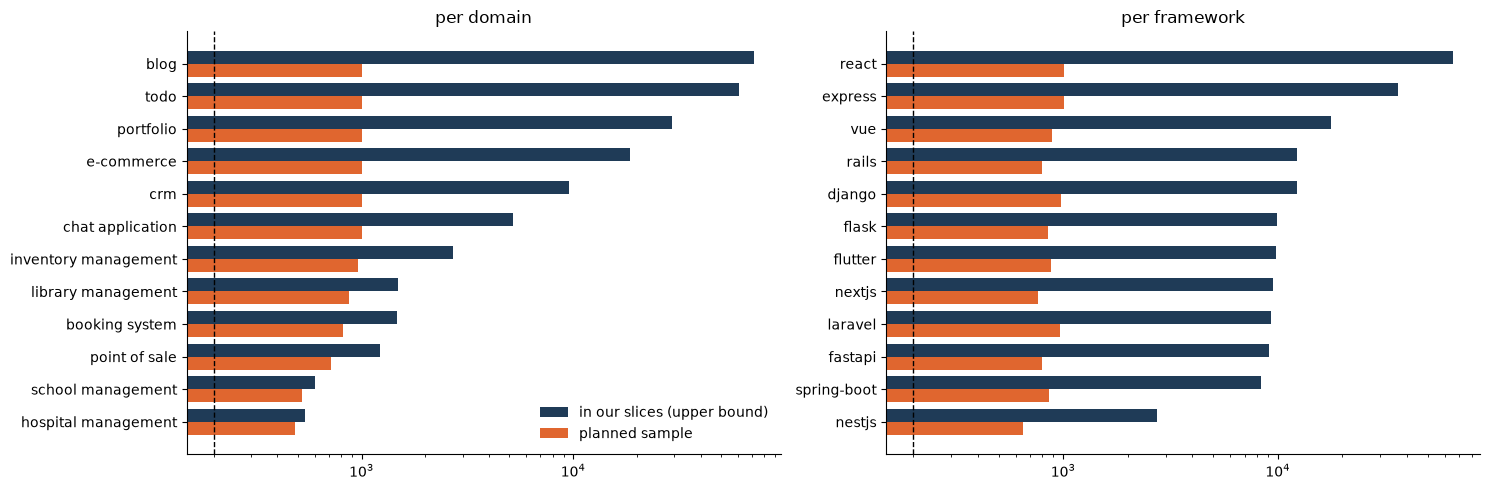

In [21]:
pop_d, take_d = grid.sum(axis=1), take.sum(axis=1)
pop_f, take_f = grid.sum(axis=0), take.sum(axis=0)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, pop, tk, title in [(ax[0], pop_d, take_d, "per domain"), (ax[1], pop_f, take_f, "per framework")]:
    order = pop.sort_values().index
    y = np.arange(len(order))
    a.barh(y + 0.2, pop[order], 0.4, color="#1f3b57", label="in our slices (upper bound)")
    a.barh(y - 0.2, tk[order], 0.4, color="#e0662f", label="planned sample")
    a.set_yticks(y, order); a.set_xscale("log"); a.axvline(200, color="black", ls="--", lw=1)
    a.set_title(title); a.spines[["top", "right"]].set_visible(False)
ax[0].legend(loc="lower right", frameon=False)
plt.tight_layout()

### 8.6 What the planned corpus is made of

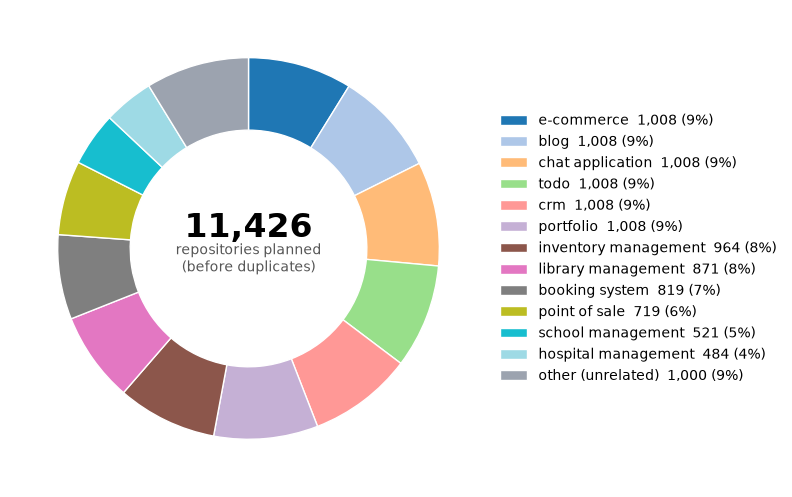

In [22]:
parts = take_d.sort_values(ascending=False)
parts["other (unrelated)"] = other["take"].sum()
fig, ax = plt.subplots(figsize=(8, 8))
cols = list(plt.cm.tab20(np.linspace(0, 1, len(parts) - 1))) + ["#9ca3af"]
wedges, _ = ax.pie(parts, colors=cols, startangle=90, counterclock=False, wedgeprops={"width": 0.38, "edgecolor": "white"})
ax.text(0, 0.06, f"{parts.sum():,}", ha="center", fontsize=24, fontweight="bold")
ax.text(0, -0.12, "repositories planned\n(before duplicates)", ha="center", fontsize=10, color="#555")
ax.legend(wedges, [f"{k}  {v:,} ({v / parts.sum():.0%})" for k, v in parts.items()], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()

## Decision

**We collect with the plan in `config/slices.csv`.** It is the table above:

- **Search the README too** (`in:name,description,topics,readme`). Without it we found 36 repositories for "inventory management" django; with it, 219. Most projects name their framework only in the README. The price: about 1 in 3 results only mention the domain in passing (the near misses), which is the noise ranking has to handle.
- **Stars ≥ 5** do the cutting: from about 22.5 million live repositories that mention a domain to 489,835. Everything below 5 is mostly personal practice projects.
- **144 slices → 442 pieces.** 41 slices were over 1,000 and were split by stars (log-scale halves); single star values still over 1,000 (like "blog" react at exactly 5 stars) were split by creation date. No piece is over 1,000, so every repository in a piece can be listed.
- **Cap per slice Q = 84.** Popular slices (blog react: 20,753) give 84 at random, small ones are kept whole. Every domain ends up between 484 and 1,008, every framework between 648 and 1,008: no domain or stack drowns the others.
- **1,000 unrelated repositories** (10 topics × 100) so every query has clear non-relevant results.
- **Planned: 11,421 before removing duplicates → about 10,000.**

**What this leaves out, on purpose** (for the report's limitations section):
- Projects in other stacks (Java without Spring, plain PHP, C#, Go, …) and projects that never name a framework: the 12 frameworks reach 41% of all ≥ 5-star repositories that mention a domain (31–36% for blog and todo, over 85% for most others).
- Repositories with under 5 stars.
- The sample is drawn from GitHub's count on the day we list; counts drift by a few each day.

**Cost of Phase 3:** listing all 442 pieces is at most 2,345 search pages (~82 min); fetching README + languages + contributors for ~10,000 repositories is ~30,000 core requests (~6–8 h).